In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [37]:
import os
from google.colab import files

if not os.path.exists("application_train.csv"):
    uploaded = files.upload()
df = pd.read_csv("application_train.csv")
print(df.shape)
df.head()

(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [38]:
print("linhas x colunas", df.shape)
print("memoria (MB):", round(df.memory_usage(deep=True).sum() / 1024**2, 2))
print("\nTipos de variáveis:")
print(df.dtypes.value_counts())

linhas x colunas (307511, 122)
memoria (MB): 504.99

Tipos de variáveis:
float64    65
int64      41
object     16
Name: count, dtype: int64


           qtd      %
TARGET               
0       282686  91.93
1        24825   8.07
Razão adimplente:inadimplente = 11.4 : 1


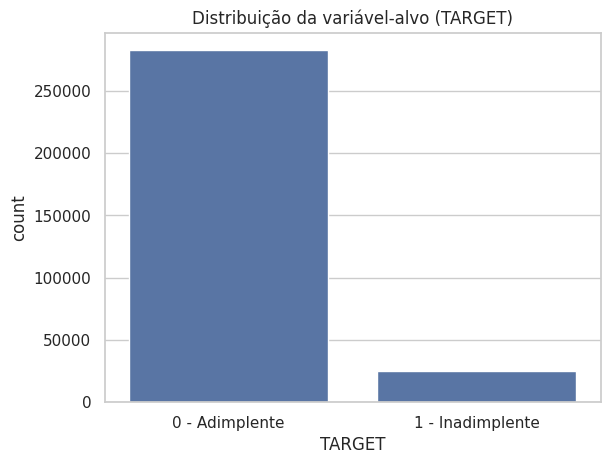

In [39]:
cont = df["TARGET"].value_counts().sort_index()
pct = (df["TARGET"].value_counts(normalize=True).sort_index() * 100).round(2)
print(pd.DataFrame({"qtd": cont, "%": pct}))
print("Razão adimplente:inadimplente = %.1f : 1" % (cont[0] / cont[1]))

ax = sns.countplot(x="TARGET", data=df)
ax.set_title("Distribuição da variável-alvo (TARGET)")
ax.set_xticks([0, 1])
ax.set_xticklabels(["0 - Adimplente", "1 - Inadimplente"])
plt.show()

Colunas ausentes: 67 de 122
COMMONAREA_AVG              69.87
COMMONAREA_MODE             69.87
COMMONAREA_MEDI             69.87
NONLIVINGAPARTMENTS_MEDI    69.43
NONLIVINGAPARTMENTS_MODE    69.43
NONLIVINGAPARTMENTS_AVG     69.43
FONDKAPREMONT_MODE          68.39
LIVINGAPARTMENTS_AVG        68.35
LIVINGAPARTMENTS_MEDI       68.35
LIVINGAPARTMENTS_MODE       68.35
FLOORSMIN_MODE              67.85
FLOORSMIN_AVG               67.85
FLOORSMIN_MEDI              67.85
YEARS_BUILD_AVG             66.50
YEARS_BUILD_MODE            66.50
YEARS_BUILD_MEDI            66.50
OWN_CAR_AGE                 65.99
LANDAREA_MEDI               59.38
LANDAREA_AVG                59.38
LANDAREA_MODE               59.38
dtype: float64


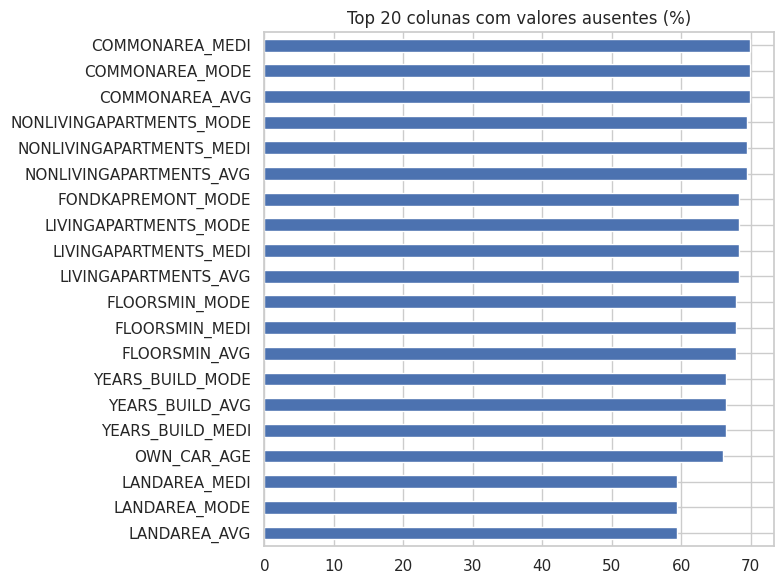

In [40]:
aus = (df.isnull().mean() * 100).sort_values(ascending=False)
aus = aus[aus > 0]
print(f"Colunas ausentes: {len(aus)} de {df.shape[1]}")
print(aus.head(20).round(2))

aus.head(20).sort_values().plot(
    kind="barh", figsize=(8, 6),
    title="Top 20 colunas com valores ausentes (%)"
)
plt.tight_layout()
plt.show()

In [41]:
cat = df.select_dtypes(exclude="number")
print("Colunas categóricas:", cat.shape[1])
print(cat.nunique().sort_values(ascending=False))

Colunas categóricas: 16
ORGANIZATION_TYPE             58
OCCUPATION_TYPE               18
NAME_INCOME_TYPE               8
NAME_TYPE_SUITE                7
WALLSMATERIAL_MODE             7
WEEKDAY_APPR_PROCESS_START     7
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
NAME_EDUCATION_TYPE            5
FONDKAPREMONT_MODE             4
HOUSETYPE_MODE                 3
CODE_GENDER                    3
FLAG_OWN_CAR                   2
NAME_CONTRACT_TYPE             2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2
dtype: int64


In [42]:
print("Linhas duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["SK_ID_CURR"].duplicated().sum())
print("DAYS_EMPLOYED == 365243:", (df["DAYS_EMPLOYED"] == 365243).sum())

print("\nIdade (anos):")
print((-df["DAYS_BIRTH"] / 365).describe().round(1))

print("\nRegistros com CODE_GENDER == 'XNA':", (df["CODE_GENDER"] == "XNA").sum())
print("\nRenda total:")
print(df["AMT_INCOME_TOTAL"].describe().round(0))

Linhas duplicadas: 0
IDs duplicados: 0
DAYS_EMPLOYED == 365243: 55374

Idade (anos):
count    307511.0
mean         43.9
std          12.0
min          20.5
25%          34.0
50%          43.2
75%          53.9
max          69.1
Name: DAYS_BIRTH, dtype: float64

Registros com CODE_GENDER == 'XNA': 4

Renda total:
count       307511.0
mean        168798.0
std         237123.0
min          25650.0
25%         112500.0
50%         147150.0
75%         202500.0
max      117000000.0
Name: AMT_INCOME_TOTAL, dtype: float64


In [43]:
dados = df.copy()
dados["DAYS_EMPLOYED_ANOM"] = (dados["DAYS_EMPLOYED"] == 365243).astype(int)
dados["DAYS_EMPLOYED"] = dados["DAYS_EMPLOYED"].replace(365243, np.nan)
dados["CODE_GENDER"] = dados["CODE_GENDER"].replace("XNA", np.nan)
dados["AMT_INCOME_TOTAL"] = np.log1p(dados["AMT_INCOME_TOTAL"])
dados = dados.drop(columns=["SK_ID_CURR"])
print("Após limpeza:", dados.shape)

Após limpeza: (307511, 122)


In [44]:
from sklearn.model_selection import train_test_split

X = dados.drop(columns=["TARGET"])
y = dados["TARGET"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print(f"Inadimplentes no treino: {y_treino.mean()*100:.2f}% | no teste: {y_teste.mean()*100:.2f}%")

Treino: (246008, 121) | Teste: (61503, 121)
Inadimplentes no treino: 8.07% | no teste: 8.07%


In [45]:
LIMITE = 0.60
ausentes_treino = X_treino.isnull().mean()
remover = ausentes_treino[ausentes_treino > LIMITE].index.tolist()
print(f"Colunas removidas (> {LIMITE*100:.0f}% ausentes no treino): {len(remover)}")
X_treino = X_treino.drop(columns=remover)
X_teste = X_teste.drop(columns=remover)
print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)

Colunas removidas (> 60% ausentes no treino): 17
Treino: (246008, 104) | Teste: (61503, 104)


In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_treino.select_dtypes(include="number").columns.tolist()
cat_cols = X_treino.select_dtypes(exclude="number").columns.tolist()
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessador = ColumnTransformer([("num", num_pipe, num_cols),
                                    ("cat", cat_pipe, cat_cols)])
print("Variáveis numéricas:", len(num_cols), "| categóricas:", len(cat_cols))

Variáveis numéricas: 89 | categóricas: 15


In [50]:
import time
from google.colab import files
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas = ["roc_auc", "recall", "precision", "f1", "accuracy"]
resultados, cv_resultados, probs, matrizes, pipes = {}, {}, {}, {}, {}

def avaliar(nome, clf, arquivo):
    t0 = time.time()
    pipe = SkPipeline([("prep", preprocessador), ("clf", clf)])

    cvr = cross_validate(pipe, X_treino, y_treino, cv=cv, scoring=metricas, n_jobs=1)
    cv_resultados[nome] = {m: (cvr[f"test_{m}"].mean(), cvr[f"test_{m}"].std()) for m in metricas}
    print(f"{nome.upper()} - VALIDAÇÃO CRUZADA (5 folds) - média ± desvio-padrão")
    for m in metricas:
        mu, sd = cv_resultados[nome][m]
        print(f"  {m:10s}: {mu:.4f} ± {sd:.4f}")

    pipe.fit(X_treino, y_treino)
    prob = pipe.predict_proba(X_teste)[:, 1]
    pred = (prob >= 0.5).astype(int)
    resultados[nome] = {
        "AUC-ROC": roc_auc_score(y_teste, prob), "Recall": recall_score(y_teste, pred),
        "Precisão": precision_score(y_teste, pred, zero_division=0),
        "F1": f1_score(y_teste, pred), "Acurácia": accuracy_score(y_teste, pred)}
    probs[nome], matrizes[nome], pipes[nome] = prob, confusion_matrix(y_teste, pred), pipe

    print(f"\n{nome.upper()} - CONJUNTO DE TESTE")
    for k, v in resultados[nome].items():
        print(f"  {k:10s}: {v:.4f}")
    print("\nMatriz de confusão (linhas: real 0/1; colunas: previsto 0/1):")
    print(matrizes[nome])

    fpr, tpr, _ = roc_curve(y_teste, prob)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {resultados[nome]['AUC-ROC']:.3f})")
    plt.plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
    plt.xlabel("Taxa de falsos positivos")
    plt.ylabel("Taxa de verdadeiros positivos")
    plt.title(f"Curva ROC - {nome}")
    plt.legend()
    plt.savefig(arquivo, dpi=150, bbox_inches="tight")
    plt.show()
    files.download(arquivo)
    print(f"\nConcluído em {(time.time()-t0)/60:.1f} min")
    return pipe

REGRESSÃO LOGÍSTICA - VALIDAÇÃO CRUZADA (5 folds) - média ± desvio-padrão
  roc_auc   : 0.7455 ± 0.0027
  recall    : 0.6768 ± 0.0069
  precision : 0.1603 ± 0.0018
  f1        : 0.2592 ± 0.0026
  accuracy  : 0.6876 ± 0.0032

REGRESSÃO LOGÍSTICA - CONJUNTO DE TESTE
  AUC-ROC   : 0.7482
  Recall    : 0.6763
  Precisão  : 0.1610
  F1        : 0.2601
  Acurácia  : 0.6894

Matriz de confusão (linhas: real 0/1; colunas: previsto 0/1):
[[39041 17497]
 [ 1607  3358]]


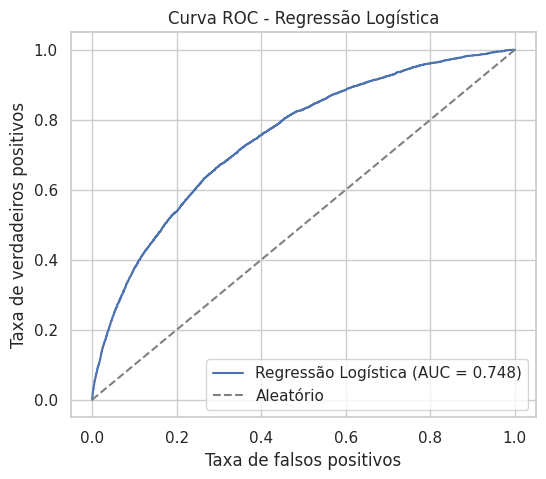

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Concluído em 3.0 min

Top 10 coeficientes (por valor absoluto):
num__AMT_GOODS_PRICE                       -0.976347
num__AMT_CREDIT                             0.918662
cat__ORGANIZATION_TYPE_Realtor              0.765061
cat__ORGANIZATION_TYPE_Legal Services       0.561694
cat__ORGANIZATION_TYPE_Transport: type 3    0.526578
cat__NAME_EDUCATION_TYPE_Academic degree   -0.503157
num__EXT_SOURCE_3                          -0.479699
cat__NAME_INCOME_TYPE_Pensioner            -0.456335
cat__ORGANIZATION_TYPE_Military            -0.442984
cat__ORGANIZATION_TYPE_Trade: type 6       -0.401930
dtype: float64


In [51]:
modelo_lr = avaliar(
    "Regressão Logística",
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "roc_regressao_logistica.png")

nomes = modelo_lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(modelo_lr.named_steps["clf"].coef_[0], index=nomes)
print("\nTop 10 coeficientes (por valor absoluto):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(10))

RANDOM FOREST - VALIDAÇÃO CRUZADA (5 folds) - média ± desvio-padrão
  roc_auc   : 0.7283 ± 0.0019
  recall    : 0.5700 ± 0.0035
  precision : 0.1697 ± 0.0022
  f1        : 0.2616 ± 0.0030
  accuracy  : 0.7402 ± 0.0027

RANDOM FOREST - CONJUNTO DE TESTE
  AUC-ROC   : 0.7339
  Recall    : 0.5831
  Precisão  : 0.1717
  F1        : 0.2653
  Acurácia  : 0.7393

Matriz de confusão (linhas: real 0/1; colunas: previsto 0/1):
[[42572 13966]
 [ 2070  2895]]


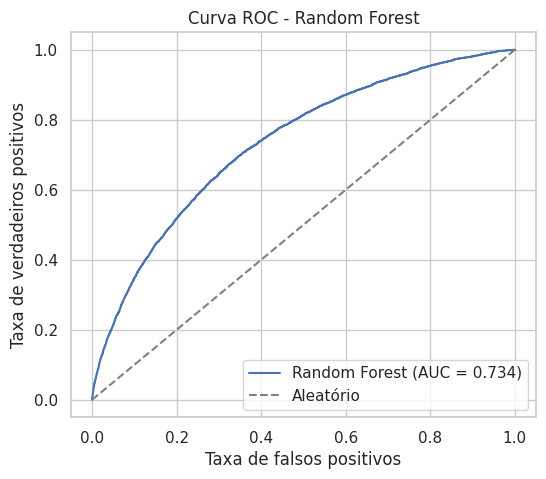

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Concluído em 7.2 min

Top 10 importâncias:
num__EXT_SOURCE_3              0.156304
num__EXT_SOURCE_2              0.133790
num__EXT_SOURCE_1              0.057605
num__DAYS_EMPLOYED             0.046044
num__DAYS_BIRTH                0.037818
num__DAYS_LAST_PHONE_CHANGE    0.027675
num__AMT_GOODS_PRICE           0.025387
num__AMT_CREDIT                0.023889
num__DAYS_ID_PUBLISH           0.022480
num__AMT_ANNUITY               0.020736
dtype: float64


In [52]:
modelo_rf = avaliar(
    "Random Forest",
    RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20,
        max_features="sqrt", class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "roc_random_forest.png")

nomes = modelo_rf.named_steps["prep"].get_feature_names_out()
imp_rf = pd.Series(modelo_rf.named_steps["clf"].feature_importances_, index=nomes)
print("\nTop 10 importâncias:")
print(imp_rf.sort_values(ascending=False).head(10))

scale_pos_weight = 11.39

XGBOOST - VALIDAÇÃO CRUZADA (5 folds) - média ± desvio-padrão
  roc_auc   : 0.7552 ± 0.0012
  recall    : 0.6726 ± 0.0047
  precision : 0.1661 ± 0.0011
  f1        : 0.2663 ± 0.0017
  accuracy  : 0.7009 ± 0.0014

XGBOOST - CONJUNTO DE TESTE
  AUC-ROC   : 0.7598
  Recall    : 0.6846
  Precisão  : 0.1678
  F1        : 0.2695
  Acurácia  : 0.7004

Matriz de confusão (linhas: real 0/1; colunas: previsto 0/1):
[[39678 16860]
 [ 1566  3399]]


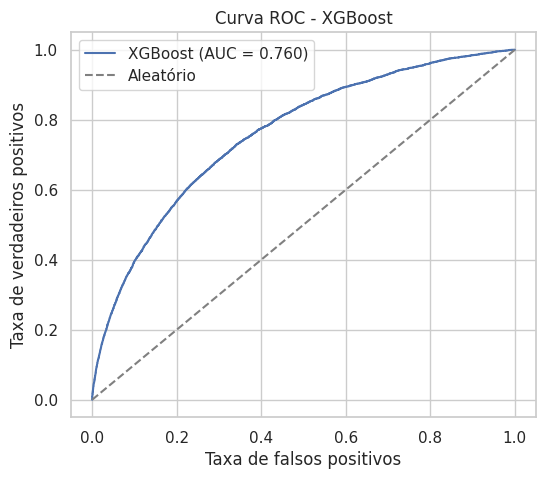

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Concluído em 3.6 min

Top 10 importâncias:
num__EXT_SOURCE_3                            0.054989
num__EXT_SOURCE_2                            0.054442
cat__NAME_EDUCATION_TYPE_Higher education    0.031523
cat__NAME_INCOME_TYPE_Working                0.023475
num__FLAG_DOCUMENT_3                         0.020945
cat__CODE_GENDER_F                           0.019572
cat__CODE_GENDER_M                           0.018499
num__EXT_SOURCE_1                            0.017691
num__DAYS_EMPLOYED                           0.015070
cat__FLAG_OWN_CAR_N                          0.014079
dtype: float32


In [53]:
peso = (y_treino == 0).sum() / (y_treino == 1).sum()
print(f"scale_pos_weight = {peso:.2f}\n")

modelo_xgb = avaliar(
    "XGBoost",
    XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, tree_method="hist", scale_pos_weight=peso,
        eval_metric="auc", n_jobs=-1, random_state=SEED),
    "roc_xgboost.png")

nomes = modelo_xgb.named_steps["prep"].get_feature_names_out()
imp_xgb = pd.Series(modelo_xgb.named_steps["clf"].feature_importances_, index=nomes)
print("\nTop 10 importâncias:")
print(imp_xgb.sort_values(ascending=False).head(10))

===== CONJUNTO DE TESTE - COMPARAÇÃO =====
                     AUC-ROC  Recall  Precisão      F1  Acurácia
Regressão Logística   0.7482  0.6763    0.1610  0.2601    0.6894
Random Forest         0.7339  0.5831    0.1717  0.2653    0.7393
XGBoost               0.7598  0.6846    0.1678  0.2695    0.7004

===== VALIDAÇÃO CRUZADA - AUC-ROC (média ± desvio) =====
Regressão Logística : 0.7455 ± 0.0027
Random Forest       : 0.7283 ± 0.0019
XGBoost             : 0.7552 ± 0.0012


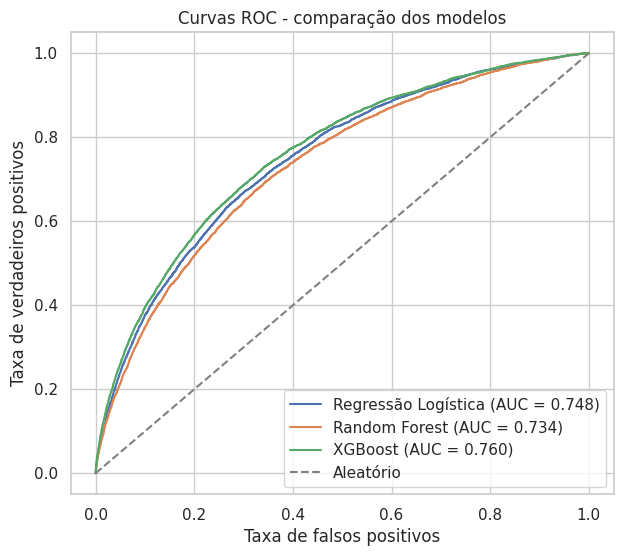

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
print("===== CONJUNTO DE TESTE - COMPARAÇÃO =====")
print(pd.DataFrame(resultados).T.round(4))

print("\n===== VALIDAÇÃO CRUZADA - AUC-ROC (média ± desvio) =====")
for nome, d in cv_resultados.items():
    mu, sd = d["roc_auc"]
    print(f"{nome:20s}: {mu:.4f} ± {sd:.4f}")

plt.figure(figsize=(7, 6))
for nome, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_teste, prob)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {resultados[nome]['AUC-ROC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Curvas ROC - comparação dos modelos")
plt.legend()
plt.savefig("roc_comparacao.png", dpi=150, bbox_inches="tight")
plt.show()
files.download("roc_comparacao.png")